In [ ]:
import os, shutil
from google.colab import drive

# Clean local mountpoint if anything exists before mounting
if os.path.exists('/content/drive') and not os.path.ismount('/content/drive'):
    shutil.rmtree('/content/drive')

drive.mount('/content/drive', force_remount=True)

WORKSPACE_DIR = "/content/drive/MyDrive/CS4045_Road_Damage_Detection"
for sub in [
    "dataset/public_rdd/train/images", "dataset/public_rdd/train/labels",
    "dataset/public_rdd/val/images",   "dataset/public_rdd/val/labels",
    "dataset/karachi_own/train/images", "dataset/karachi_own/train/labels",
    "dataset/karachi_own/val/images",   "dataset/karachi_own/val/labels",
    "dataset/karachi_own/test/images",  "dataset/karachi_own/test/labels",
    "dataset/combined/train/images",    "dataset/combined/train/labels",
    "dataset/combined/val/images",      "dataset/combined/val/labels",
    "runs", "models"
]:
    os.makedirs(os.path.join(WORKSPACE_DIR, sub), exist_ok=True)

print(" Google Drive mounted & clean project folders created at:", WORKSPACE_DIR)

Mounted at /content/drive
 Google Drive mounted & clean project folders created at: /content/drive/MyDrive/CS4045_Road_Damage_Detection


In [ ]:
import os, glob, random, shutil, zipfile, subprocess
import xml.etree.ElementTree as ET

assert os.path.ismount('/content/drive'), "❌ Pehle Cell 1 run karke Google Drive mount karein!"

WORKSPACE_DIR = "/content/drive/MyDrive/CS4045_Road_Damage_Detection"
PUBLIC_YOLO_DIR = os.path.join(WORKSPACE_DIR, "dataset", "public_rdd")
TEMP_DIR = "/content/rdd_temp"
os.makedirs(TEMP_DIR, exist_ok=True)

# 1. Download RDD2022.zip to fast Colab local disk (~4 mins)
zip_path = os.path.join(TEMP_DIR, "RDD2022.zip")
print("Step 1: Downloading RDD2022.zip...")
subprocess.run(["wget", "-q", "--show-progress", "-c", "https://ndownloader.figshare.com/files/38030910", "-O", zip_path], check=True)

# 2. Extract ONLY India.zip
print("\nStep 2: Extracting ONLY India.zip...")
with zipfile.ZipFile(zip_path, 'r') as z:
    for m in [m for m in z.namelist() if m.endswith("India.zip")]:
        z.extract(m, TEMP_DIR)

india_zip_path = glob.glob(os.path.join(TEMP_DIR, "**", "India.zip"), recursive=True)[0]
with zipfile.ZipFile(india_zip_path, 'r') as iz:
    iz.extractall(TEMP_DIR)

# 3. Parse XMLs & Convert 3,000 Images (2,400 train / 600 val) to YOLO Format
print("\nStep 3: Converting 3,000 images to YOLO format on Google Drive...")
CLASS_MAP = {
    "D40": 0,  # pothole
    "D00": 1,  # longitudinal crack
    "D01": 1,  # longitudinal crack
    "D10": 1,  # transverse crack
    "D11": 1,  # transverse crack
    "D20": 1,  # alligator crack
}

india_train_dir = os.path.join(TEMP_DIR, "India", "train")
xml_files = sorted(glob.glob(os.path.join(india_train_dir, "**", "*.xml"), recursive=True))
all_images = {
    os.path.splitext(os.path.basename(p))[0]: p
    for p in glob.glob(os.path.join(india_train_dir, "**", "*.jpg"), recursive=True)
}

valid_samples = []
for xml_path in xml_files:
    tree = ET.parse(xml_path)
    root = tree.getroot()
    size = root.find("size")
    w, h = int(size.find("width").text), int(size.find("height").text)
    if w == 0 or h == 0:
        continue

    yolo_lines = []
    for obj in root.findall("object"):
        cls_name = obj.find("name").text
        if cls_name in CLASS_MAP:
            cls_id = CLASS_MAP[cls_name]
            bndbox = obj.find("bndbox")
            xmin, ymin = float(bndbox.find("xmin").text), float(bndbox.find("ymin").text)
            xmax, ymax = float(bndbox.find("xmax").text), float(bndbox.find("ymax").text)

            x_c = max(0.0, min(1.0, ((xmin + xmax) / 2.0) / w))
            y_c = max(0.0, min(1.0, ((ymin + ymax) / 2.0) / h))
            bw = max(0.0, min(1.0, (xmax - xmin) / w))
            bh = max(0.0, min(1.0, (ymax - ymin) / h))

            if bw > 0 and bh > 0:
                yolo_lines.append(f"{cls_id} {x_c:.6f} {y_c:.6f} {bw:.6f} {bh:.6f}")

    if yolo_lines:
        base_name = os.path.splitext(os.path.basename(xml_path))[0]
        if base_name in all_images:
            valid_samples.append((all_images[base_name], base_name, yolo_lines))

random.seed(42)
random.shuffle(valid_samples)
selected = valid_samples[:3000]
splits = {"train": selected[:2400], "val": selected[2400:3000]}

pothole_count, crack_count = 0, 0
for split_name, items in splits.items():
    for img_path, base_name, yolo_lines in items:
        shutil.copy2(img_path, os.path.join(PUBLIC_YOLO_DIR, split_name, "images", base_name + ".jpg"))
        with open(os.path.join(PUBLIC_YOLO_DIR, split_name, "labels", base_name + ".txt"), "w") as f:
            f.write("\n".join(yolo_lines) + "\n")
        for line in yolo_lines:
            if line.startswith("0 "): pothole_count += 1
            elif line.startswith("1 "): crack_count += 1

# 4. Generate data.yaml & remove temp files
with open(os.path.join(PUBLIC_YOLO_DIR, "data.yaml"), "w") as f:
    f.write(f"path: {PUBLIC_YOLO_DIR}\ntrain: train/images\nval: val/images\n\nnc: 2\nnames: ['pothole', 'crack']\n")

shutil.rmtree(TEMP_DIR)

print(f"\n Public RDD Dataset Ready on Drive: {PUBLIC_YOLO_DIR}")
print(f"Train: {len(splits['train'])} | Val: {len(splits['val'])}")
print(f"Bounding Boxes -> Potholes (0): {pothole_count} | Cracks (1): {crack_count}")

Step 1: Downloading RDD2022.zip...

Step 2: Extracting ONLY India.zip...

Step 3: Converting 3,000 images to YOLO format on Google Drive...

 Public RDD Dataset Ready on Drive: /content/drive/MyDrive/CS4045_Road_Damage_Detection/dataset/public_rdd
Train: 2400 | Val: 600
Bounding Boxes -> Potholes (0): 2881 | Cracks (1): 3526


In [ ]:

!pip install -q ultralytics
import torch
print("GPU Available:", torch.cuda.is_available(), "| Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

from ultralytics import YOLO

WORKSPACE_DIR = "/content/drive/MyDrive/CS4045_Road_Damage_Detection"
DATA_YAML = f"{WORKSPACE_DIR}/dataset/public_rdd/data.yaml"

model = YOLO("yolov8n.pt")

results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=16,
    project=f"{WORKSPACE_DIR}/runs",
    name="exp1_public_rdd",
    patience=10,
    save=True
)

GPU Available: True | Device: Tesla T4
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/CS4045_Road_Damage_Detection/dataset/public_rdd/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50

✅ Model backed up to: models/exp1_public_rdd_best.pt

--- results.png ---


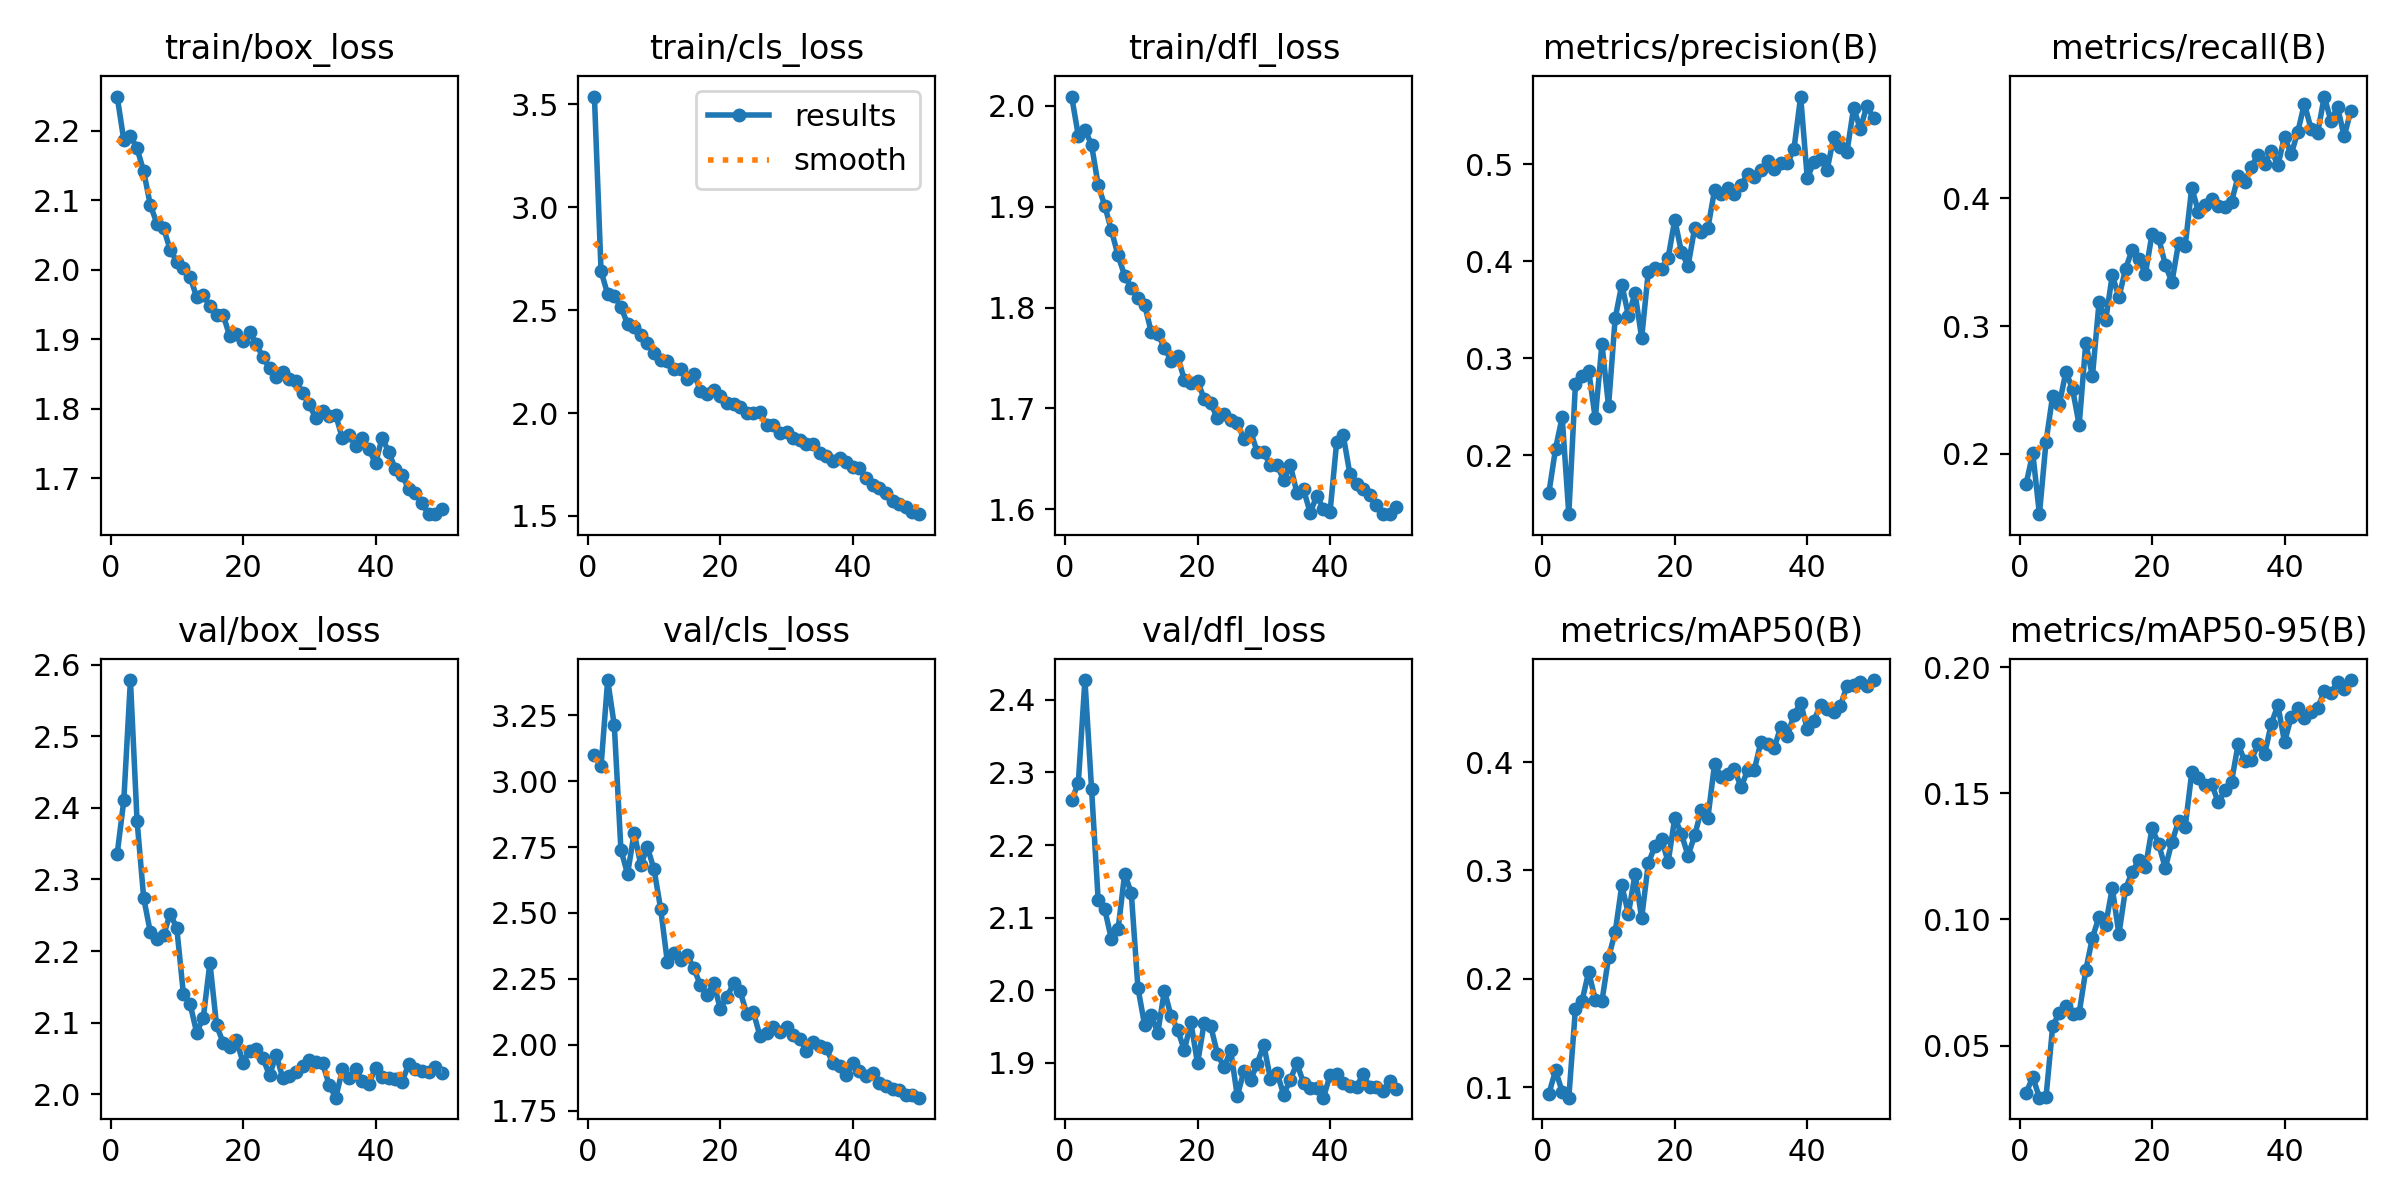


--- confusion_matrix.png ---


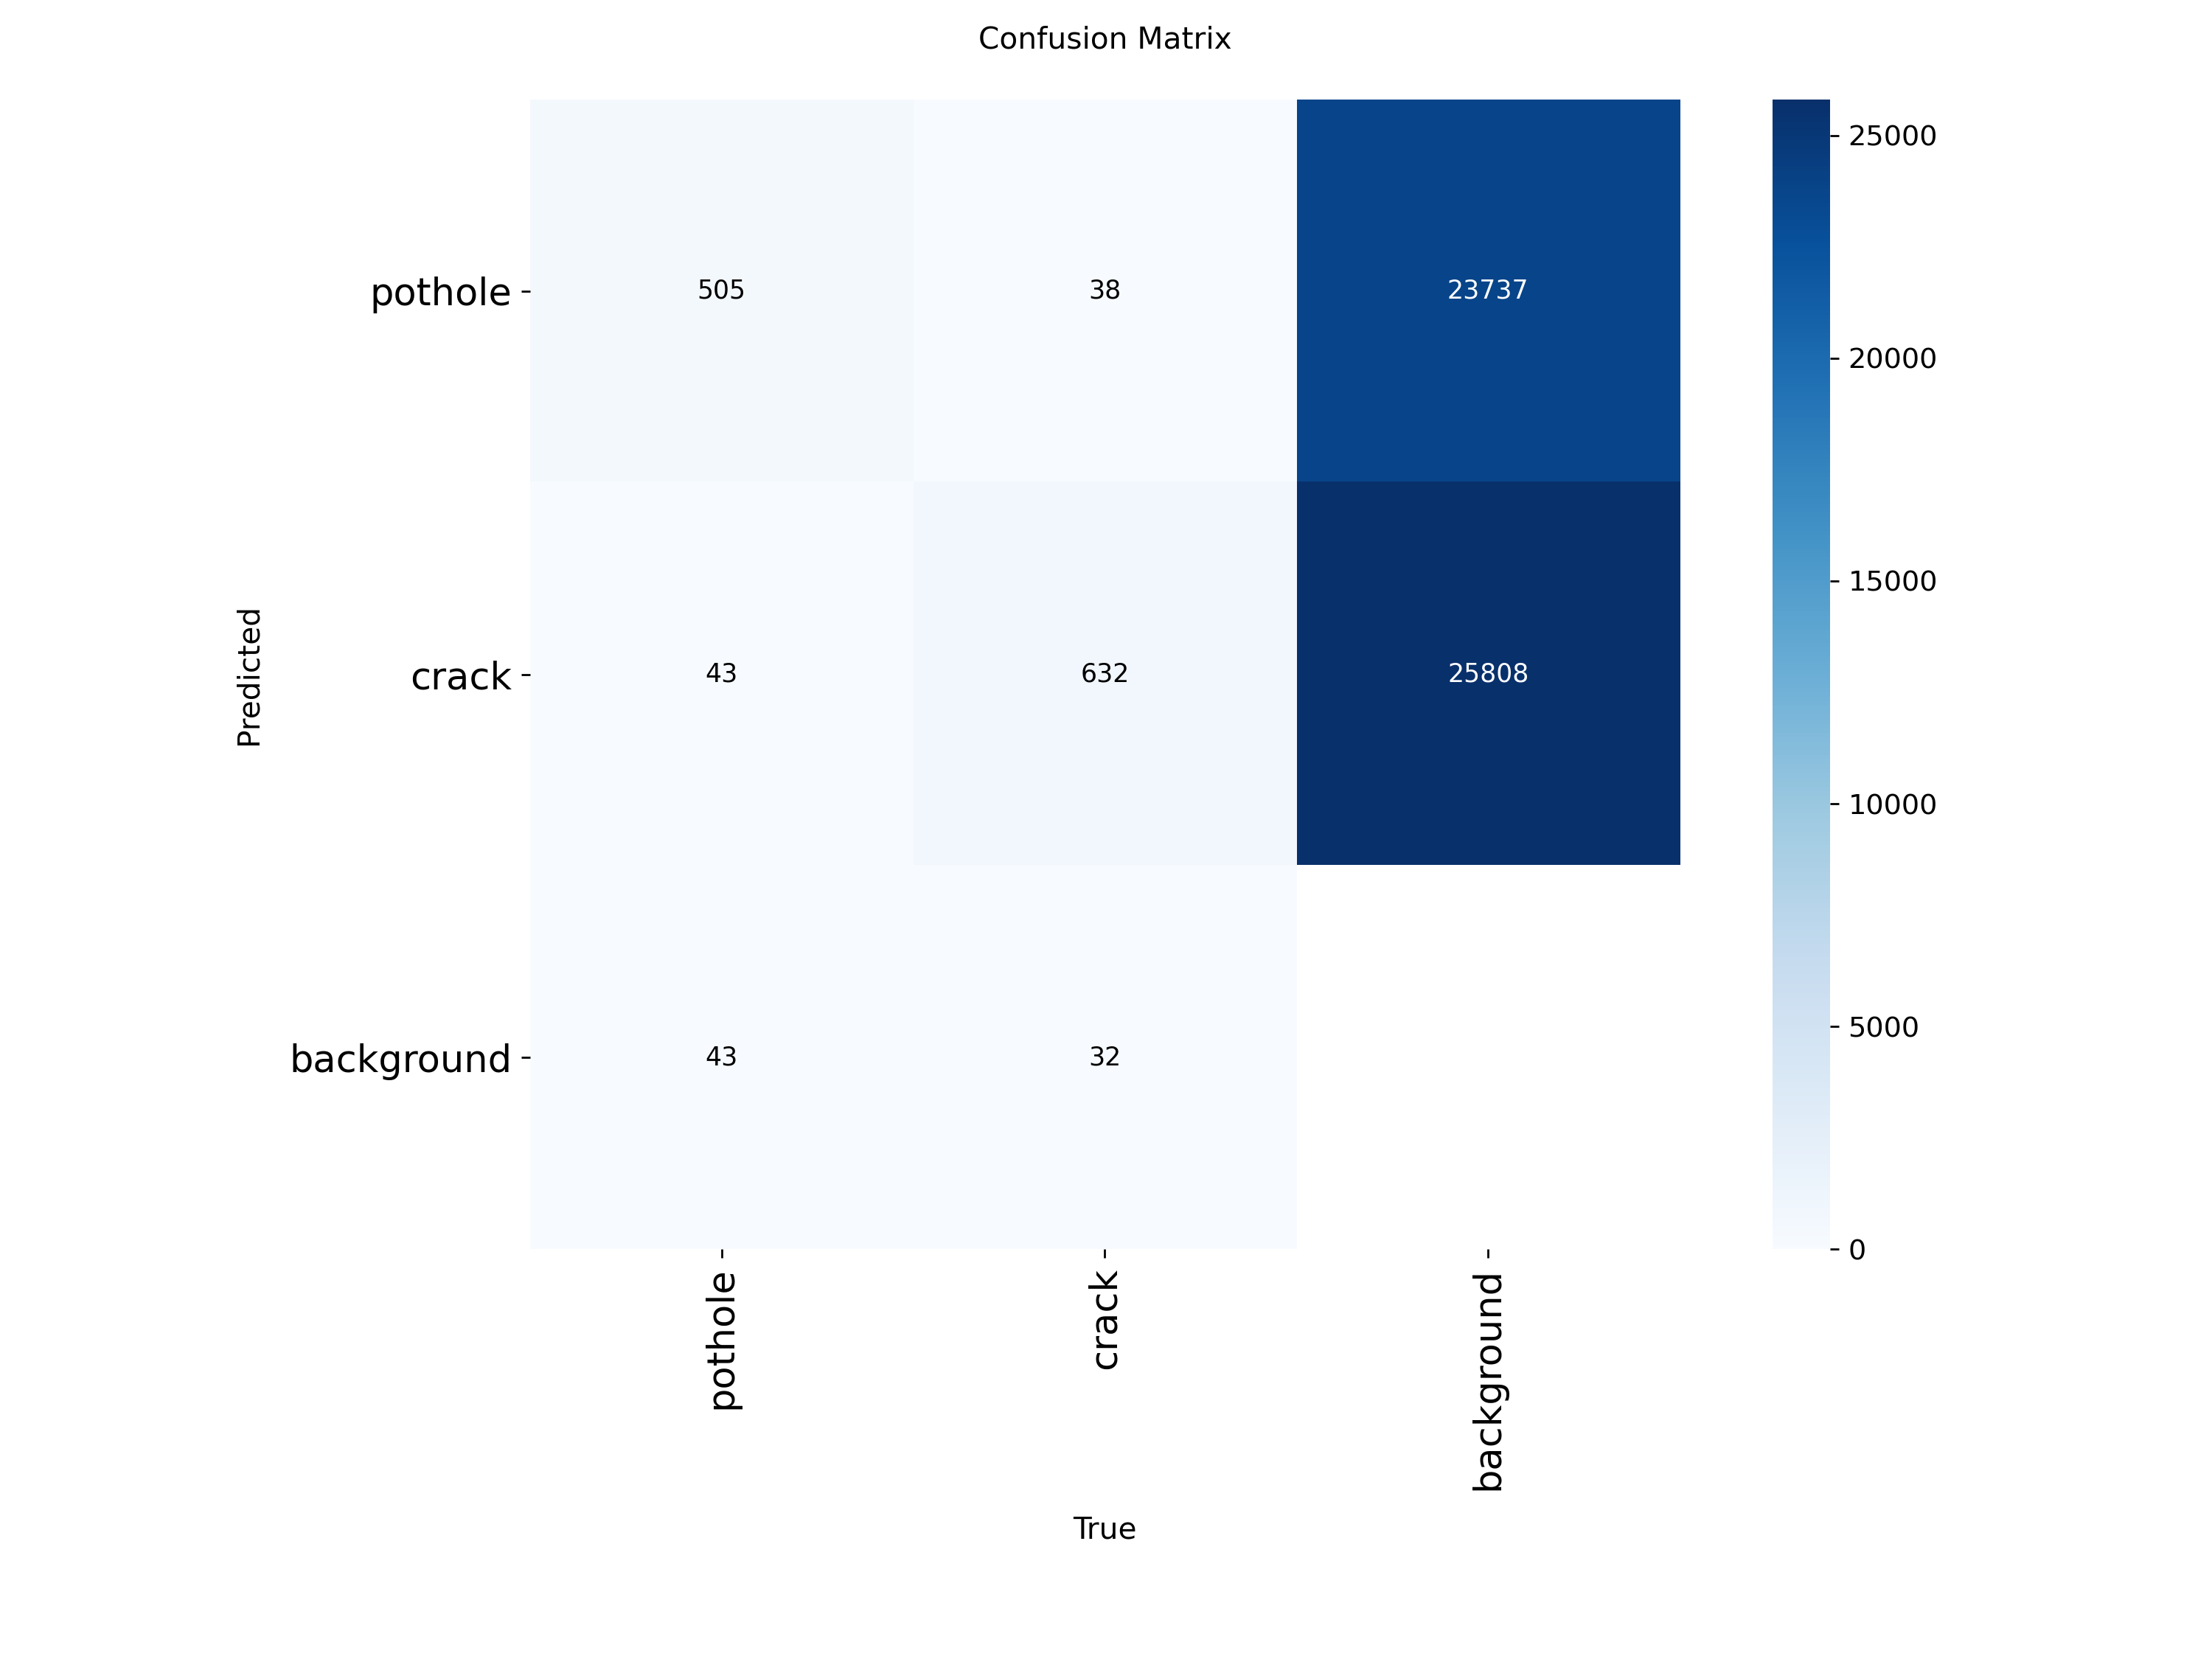


--- val_batch0_pred.jpg ---


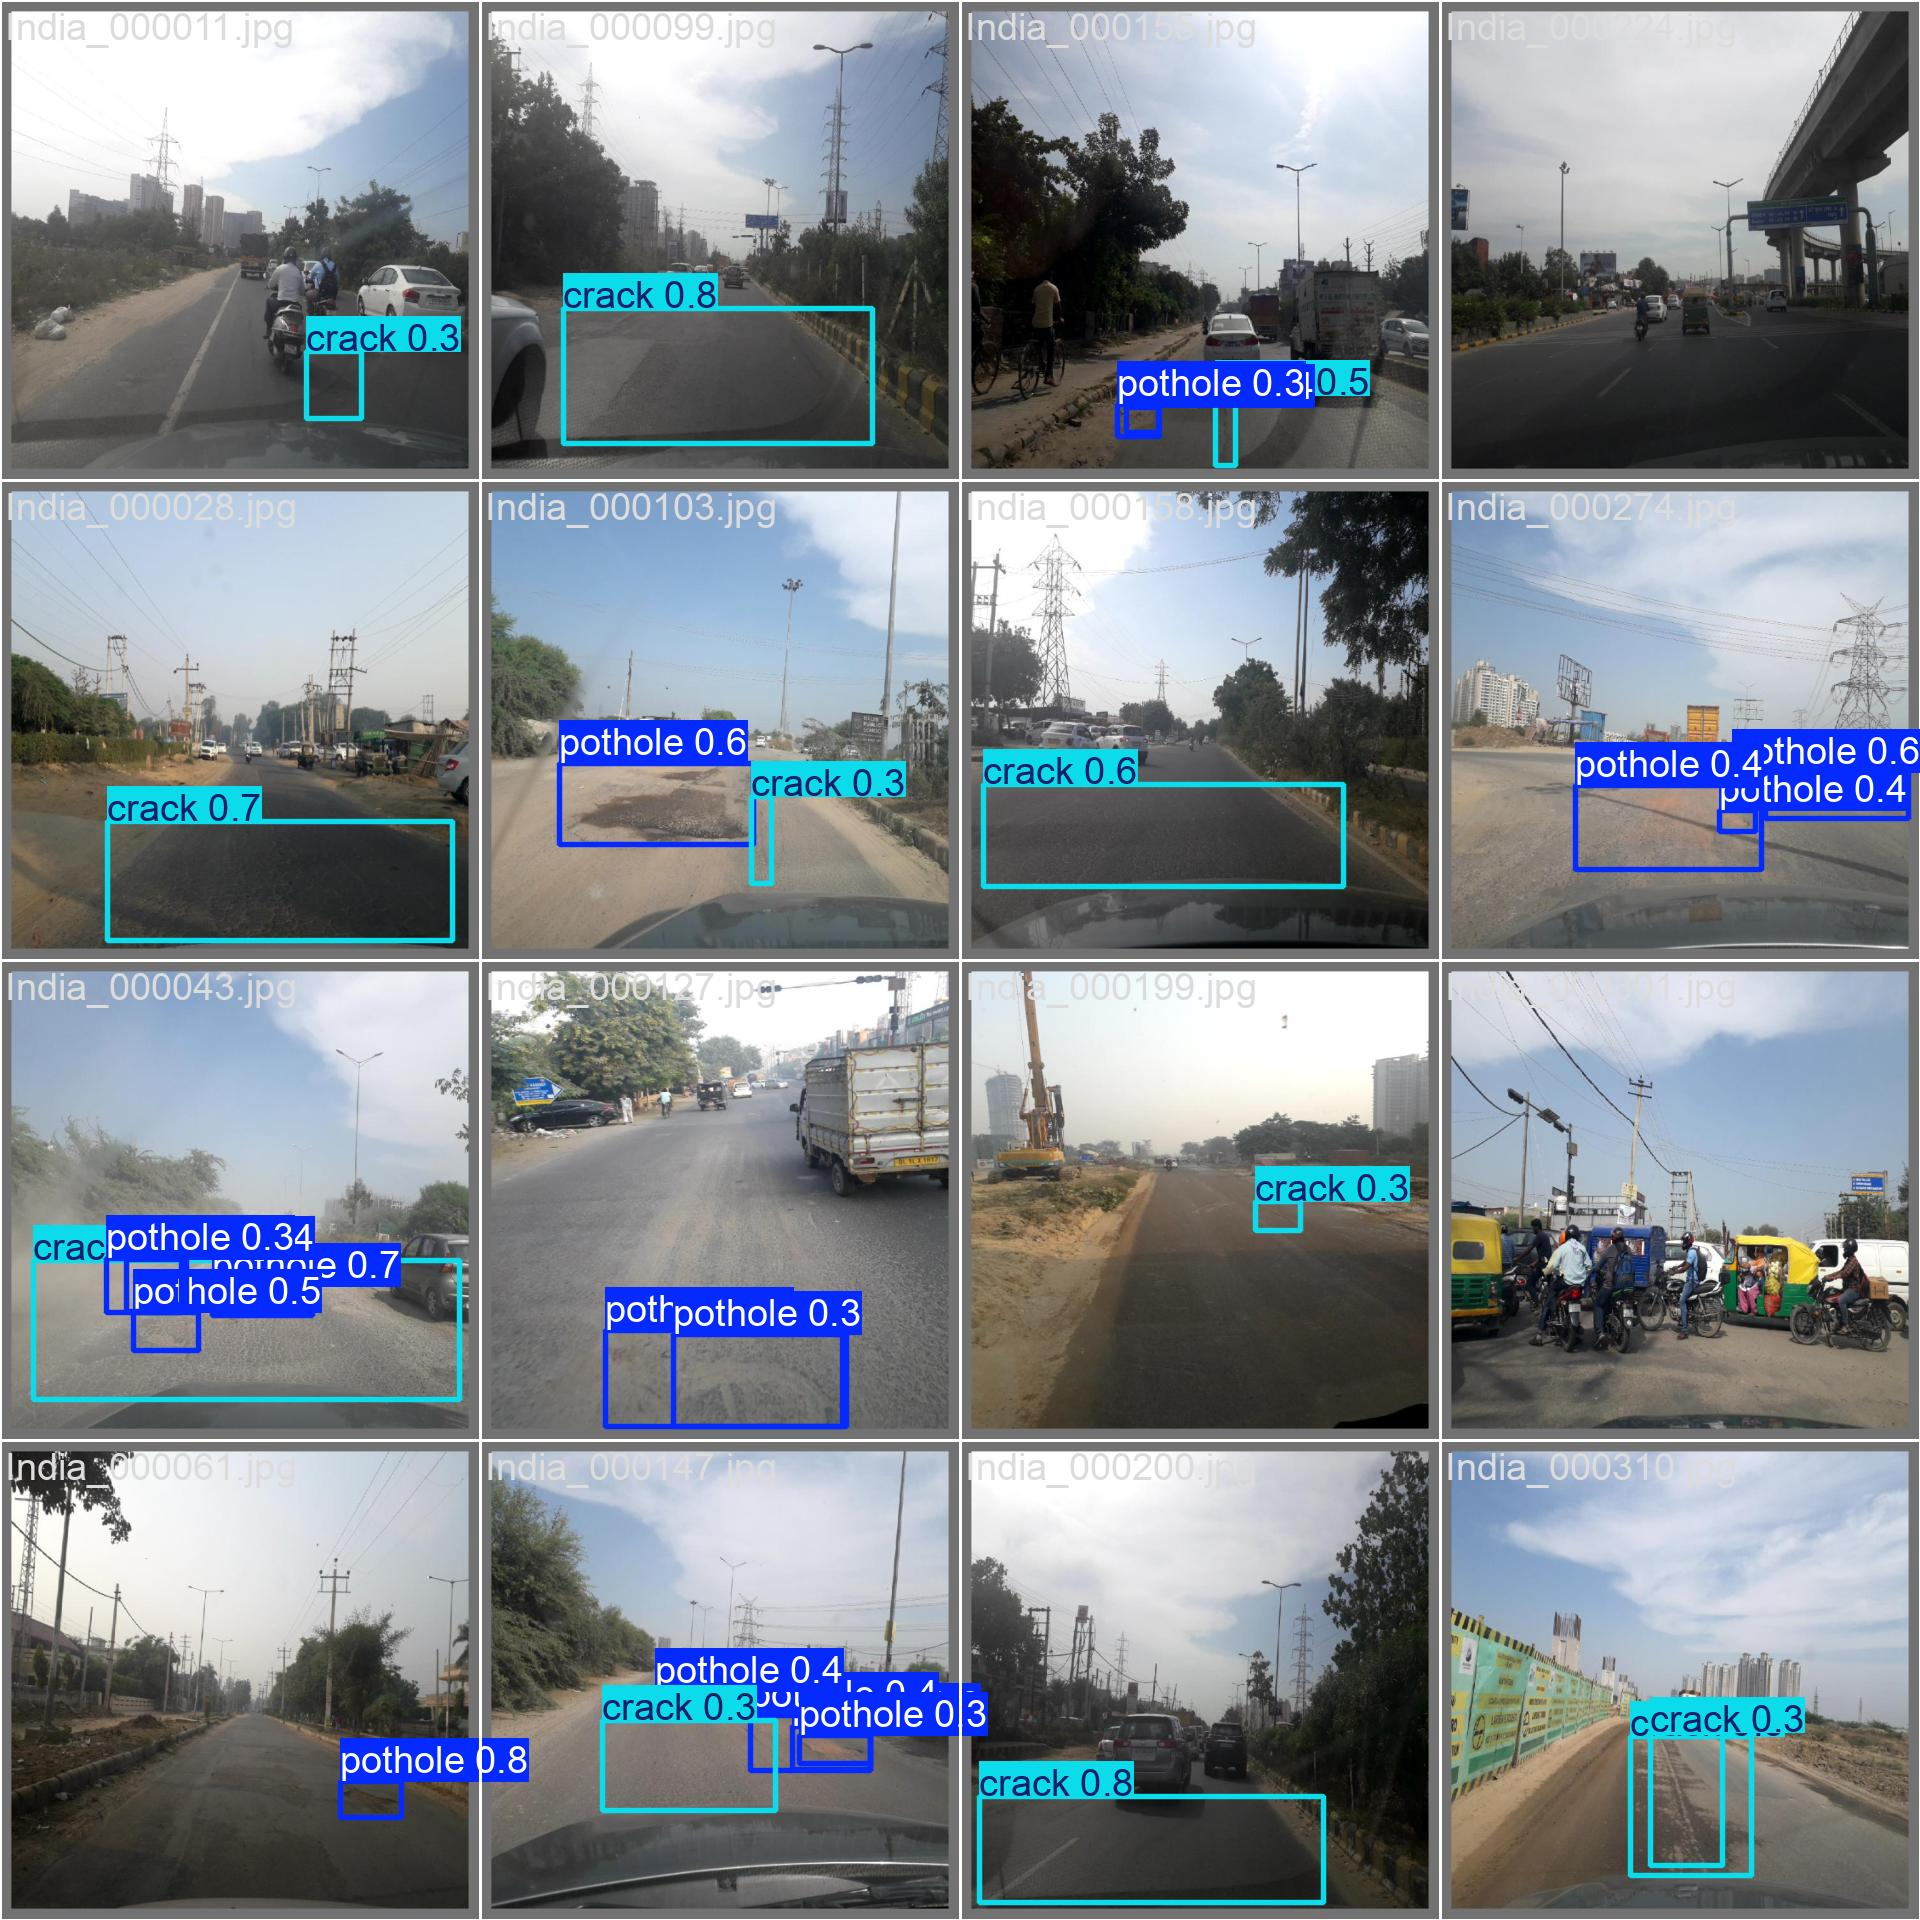

In [ ]:
import os, shutil
from IPython.display import Image, display

WORKSPACE_DIR = "/content/drive/MyDrive/CS4045_Road_Damage_Detection"
RUN_DIR = f"{WORKSPACE_DIR}/runs/exp1_public_rdd"

# 1. Best weights ko models folder mein backup karein
os.makedirs(f"{WORKSPACE_DIR}/models", exist_ok=True)
shutil.copy2(f"{RUN_DIR}/weights/best.pt", f"{WORKSPACE_DIR}/models/exp1_public_rdd_best.pt")
print("✅ Model backed up to: models/exp1_public_rdd_best.pt")

# 2. Training curves aur Confusion Matrix display karein
for img_name in ["results.png", "confusion_matrix.png", "val_batch0_pred.jpg"]:
    img_path = os.path.join(RUN_DIR, img_name)
    if os.path.exists(img_path):
        print(f"\n--- {img_name} ---")
        display(Image(filename=img_path, width=800))

In [ ]:
import os, glob, shutil
from google.colab import drive

if os.path.exists('/content/drive') and not os.path.ismount('/content/drive'):
    shutil.rmtree('/content/drive')
drive.mount('/content/drive', force_remount=True)

WORKSPACE_DIR = "/content/drive/MyDrive/CS4045_Road_Damage_Detection"
KARACHI_DIR = f"{WORKSPACE_DIR}/dataset/karachi_own"

for cf in glob.glob(f"{KARACHI_DIR}/**/classes.txt", recursive=True):
    os.remove(cf)

with open(f"{KARACHI_DIR}/data.yaml", "w") as f:
    f.write(f"path: {KARACHI_DIR}\ntrain: train/images\nval: val/images\ntest: test/images\n\nnc: 2\nnames: ['pothole', 'crack']\n")

for split in ["train", "val", "test"]:
    imgs = len(glob.glob(f"{KARACHI_DIR}/{split}/images/*.jpg"))
    lbls = len(glob.glob(f"{KARACHI_DIR}/{split}/labels/*.txt"))
    print(f"karachi_own/{split}: {imgs} images | {lbls} labels")

Mounted at /content/drive
karachi_own/train: 50 images | 50 labels
karachi_own/val: 20 images | 20 labels
karachi_own/test: 25 images | 25 labels


In [ ]:
!pip install -q ultralytics
from ultralytics import YOLO

WORKSPACE_DIR = "/content/drive/MyDrive/CS4045_Road_Damage_Detection"
baseline_model = YOLO(f"{WORKSPACE_DIR}/models/exp1_public_rdd_best.pt")

metrics_cross = baseline_model.val(
    data=f"{WORKSPACE_DIR}/dataset/karachi_own/data.yaml",
    split="test",
    imgsz=640,
    project=f"{WORKSPACE_DIR}/runs",
    name="exp1_cross_domain_karachi_test"
)
print(f"\n📊 Cross-Domain Test mAP50 (Public -> Karachi): {metrics_cross.box.map50:.4f}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.1 ms, read: 11.3±3.3 MB/s, size: 7109.5 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/CS4045_Road_Damage_Detection/dataset/karachi_own/test/labels... 25 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 25/25 1.0it/s 24.0s
val: New cache created: /content/drive/MyDrive/CS4045_Road_Damage_Detection/dataset/karachi_own/test/labels.cache
                 

In [ ]:
import os, glob, shutil
from ultralytics import YOLO

WORKSPACE_DIR = "/content/drive/MyDrive/CS4045_Road_Damage_Detection"
PUBLIC_DIR = f"{WORKSPACE_DIR}/dataset/public_rdd"
KARACHI_DIR = f"{WORKSPACE_DIR}/dataset/karachi_own"
COMBINED_DIR = f"{WORKSPACE_DIR}/dataset/combined"

# 1. Copy public_rdd train & val into combined
for split in ["train", "val"]:
    os.makedirs(f"{COMBINED_DIR}/{split}/images", exist_ok=True)
    os.makedirs(f"{COMBINED_DIR}/{split}/labels", exist_ok=True)
    for img in glob.glob(f"{PUBLIC_DIR}/{split}/images/*.jpg"):
        shutil.copy2(img, f"{COMBINED_DIR}/{split}/images/")
    for lbl in glob.glob(f"{PUBLIC_DIR}/{split}/labels/*.txt"):
        shutil.copy2(lbl, f"{COMBINED_DIR}/{split}/labels/")

# 2. Copy karachi_own train (5x oversampled) & val (1x) into combined
for rep in range(5):
    for img in glob.glob(f"{KARACHI_DIR}/train/images/*.jpg"):
        base = os.path.splitext(os.path.basename(img))[0]
        lbl = f"{KARACHI_DIR}/train/labels/{base}.txt"
        shutil.copy2(img, f"{COMBINED_DIR}/train/images/khi_r{rep}_{base}.jpg")
        if os.path.exists(lbl):
            shutil.copy2(lbl, f"{COMBINED_DIR}/train/labels/khi_r{rep}_{base}.txt")

for img in glob.glob(f"{KARACHI_DIR}/val/images/*.jpg"):
    base = os.path.splitext(os.path.basename(img))[0]
    lbl = f"{KARACHI_DIR}/val/labels/{base}.txt"
    shutil.copy2(img, f"{COMBINED_DIR}/val/images/khi_{base}.jpg")
    if os.path.exists(lbl):
        shutil.copy2(lbl, f"{COMBINED_DIR}/val/labels/khi_{base}.txt")

with open(f"{COMBINED_DIR}/data.yaml", "w") as f:
    f.write(f"path: {COMBINED_DIR}\ntrain: train/images\nval: val/images\n\nnc: 2\nnames: ['pothole', 'crack']\n")

print("✅ Combined Dataset Ready -> Train:", len(glob.glob(f"{COMBINED_DIR}/train/images/*.jpg")),
      "| Val:", len(glob.glob(f"{COMBINED_DIR}/val/images/*.jpg")))

# 3. Fine-tune from exp1_public_rdd_best.pt on Combined Dataset
ft_model = YOLO(f"{WORKSPACE_DIR}/models/exp1_public_rdd_best.pt")
ft_model.train(
    data=f"{COMBINED_DIR}/data.yaml",
    epochs=25,
    imgsz=640,
    batch=16,
    lr0=0.002,
    project=f"{WORKSPACE_DIR}/runs",
    name="exp2_combined_finetuned",
    patience=8,
    save=True
)

# 4. Evaluate Fine-Tuned Model on the SAME Karachi Test Set
best_ft = YOLO(f"{WORKSPACE_DIR}/runs/exp2_combined_finetuned/weights/best.pt")
shutil.copy2(f"{WORKSPACE_DIR}/runs/exp2_combined_finetuned/weights/best.pt", f"{WORKSPACE_DIR}/models/exp2_combined_best.pt")

metrics_ft = best_ft.val(
    data=f"{KARACHI_DIR}/data.yaml",
    split="test",
    imgsz=640,
    project=f"{WORKSPACE_DIR}/runs",
    name="exp2_karachi_test_eval"
)
print(f"\n🚀 Fine-Tuned Test mAP50 on Karachi Test Set: {metrics_ft.box.map50:.4f}")

✅ Combined Dataset Ready -> Train: 2650 | Val: 620
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/CS4045_Road_Damage_Detection/dataset/combined/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDri

In [ ]:
import shutil
from ultralytics import YOLO

WORKSPACE_DIR = "/content/drive/MyDrive/CS4045_Road_Damage_Detection"
KARACHI_DIR = f"{WORKSPACE_DIR}/dataset/karachi_own"

# Experiment 3: Fine-tune Exp 1 model directly on Karachi train/val with frozen backbone & low LR
karachi_ft = YOLO(f"{WORKSPACE_DIR}/models/exp1_public_rdd_best.pt")
karachi_ft.train(
    data=f"{KARACHI_DIR}/data.yaml",
    epochs=30,
    imgsz=640,
    batch=8,
    optimizer="AdamW",
    lr0=0.0005,
    freeze=10,
    project=f"{WORKSPACE_DIR}/runs",
    name="exp3_karachi_domain_adapted",
    patience=15,
    save=True
)

# Backup best model & evaluate on Karachi Test Set
best_exp3_path = f"{WORKSPACE_DIR}/runs/exp3_karachi_domain_adapted/weights/best.pt"
shutil.copy2(best_exp3_path, f"{WORKSPACE_DIR}/models/exp3_karachi_adapted_best.pt")

best_exp3 = YOLO(best_exp3_path)
metrics_exp3 = best_exp3.val(
    data=f"{KARACHI_DIR}/data.yaml",
    split="test",
    imgsz=640,
    project=f"{WORKSPACE_DIR}/runs",
    name="exp3_karachi_test_eval"
)
print(f"\n🎯 Exp 3 (Domain-Adapted) Test mAP50 on Karachi Test Set: {metrics_exp3.box.map50:.4f}")

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/CS4045_Road_Damage_Detection/dataset/karachi_own/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/CS4045_Road_Damage_Detection/models/exp1_public


=== exp1_cross_domain_karachi_test ===


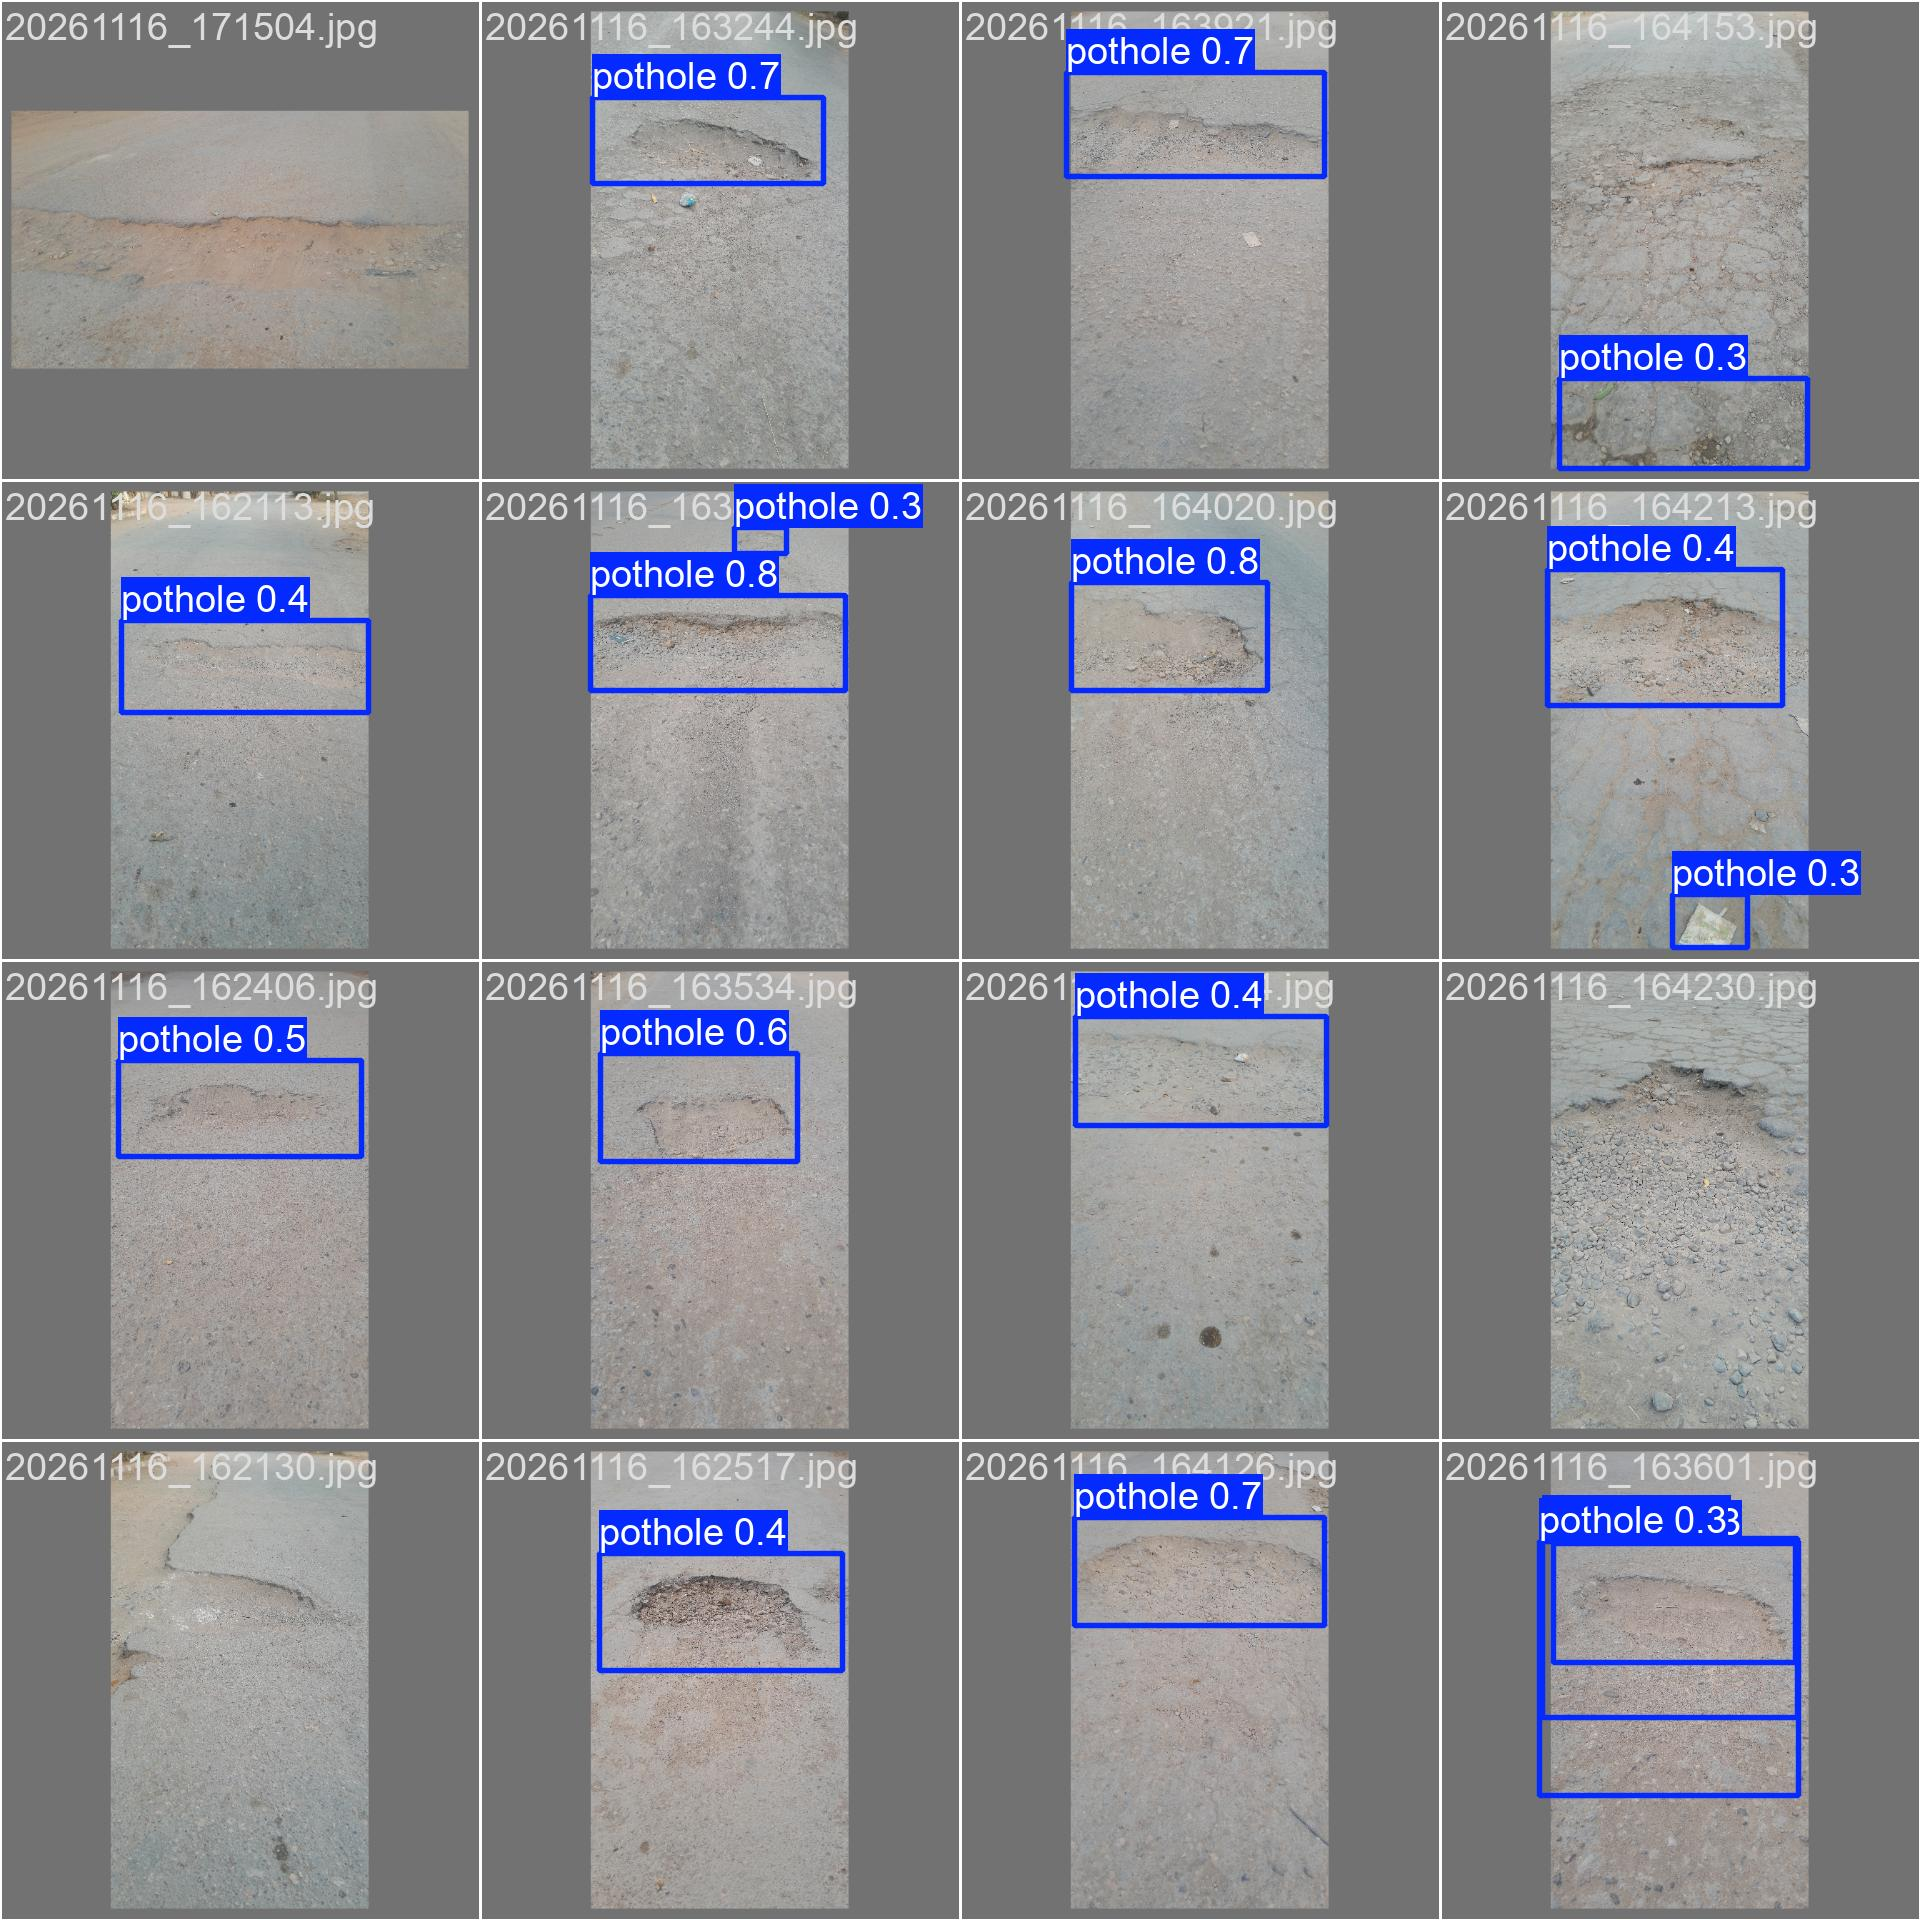


=== exp2_karachi_test_eval ===


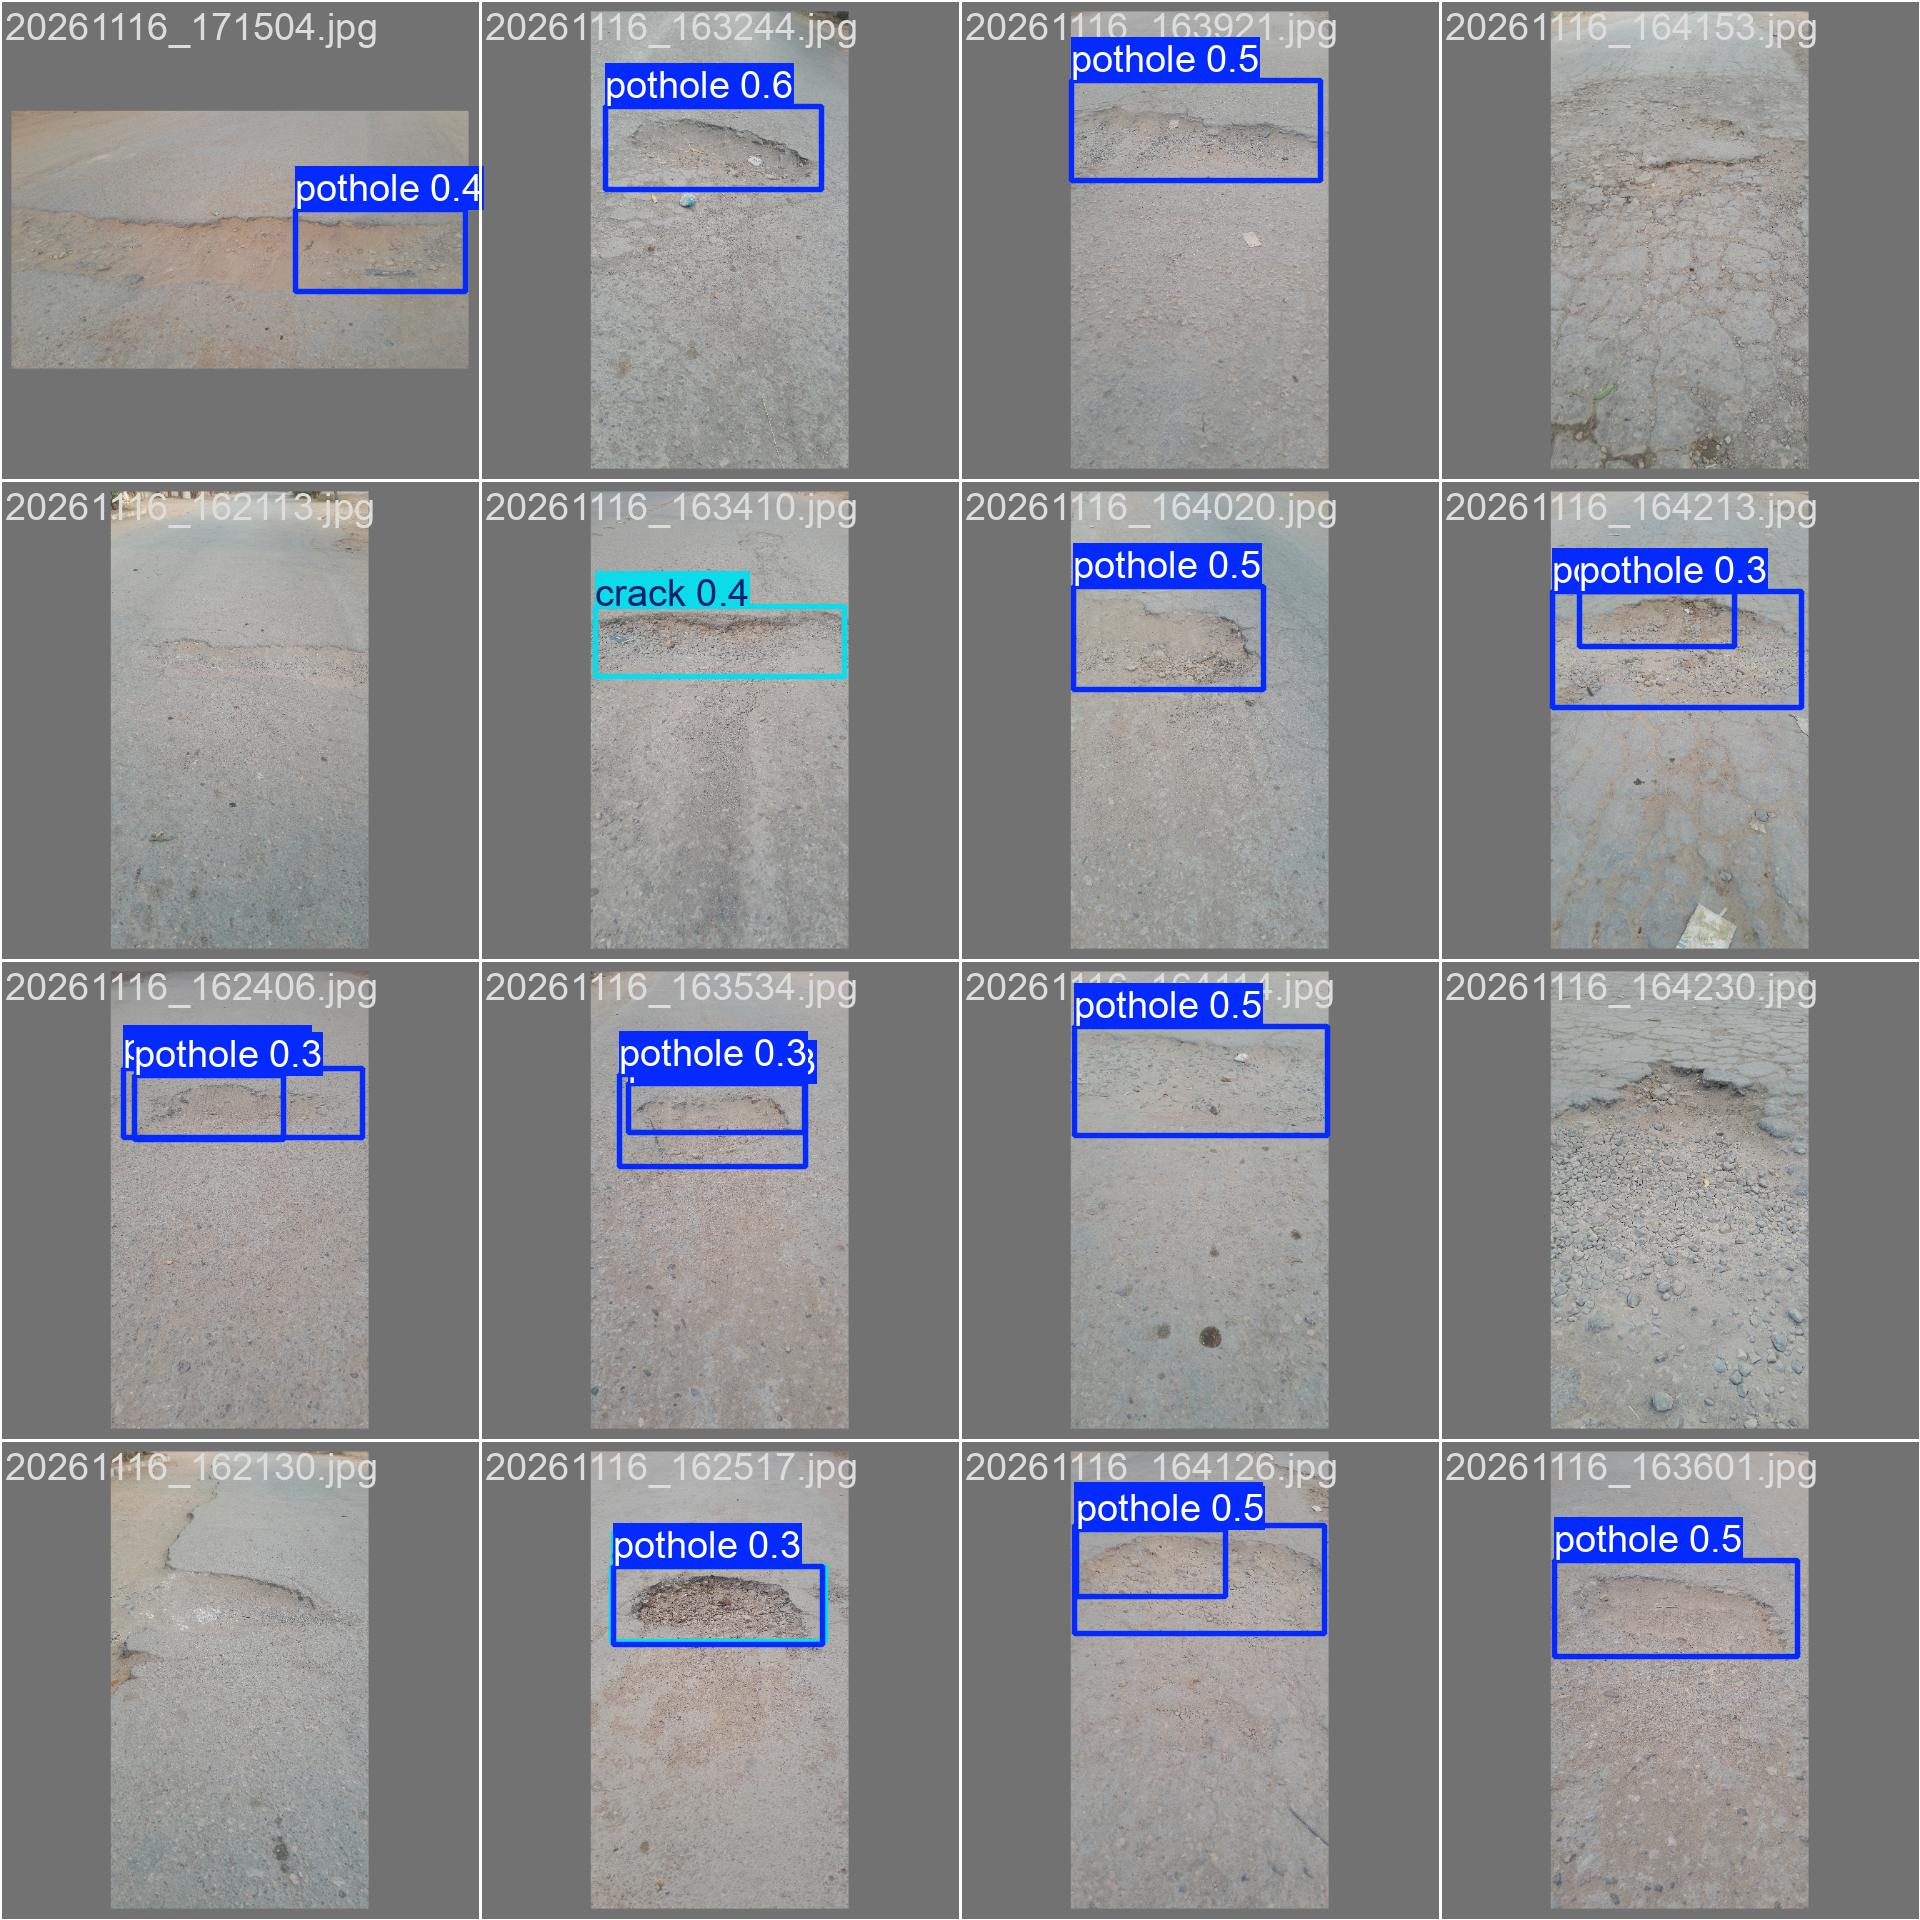


=== exp3_karachi_test_eval ===


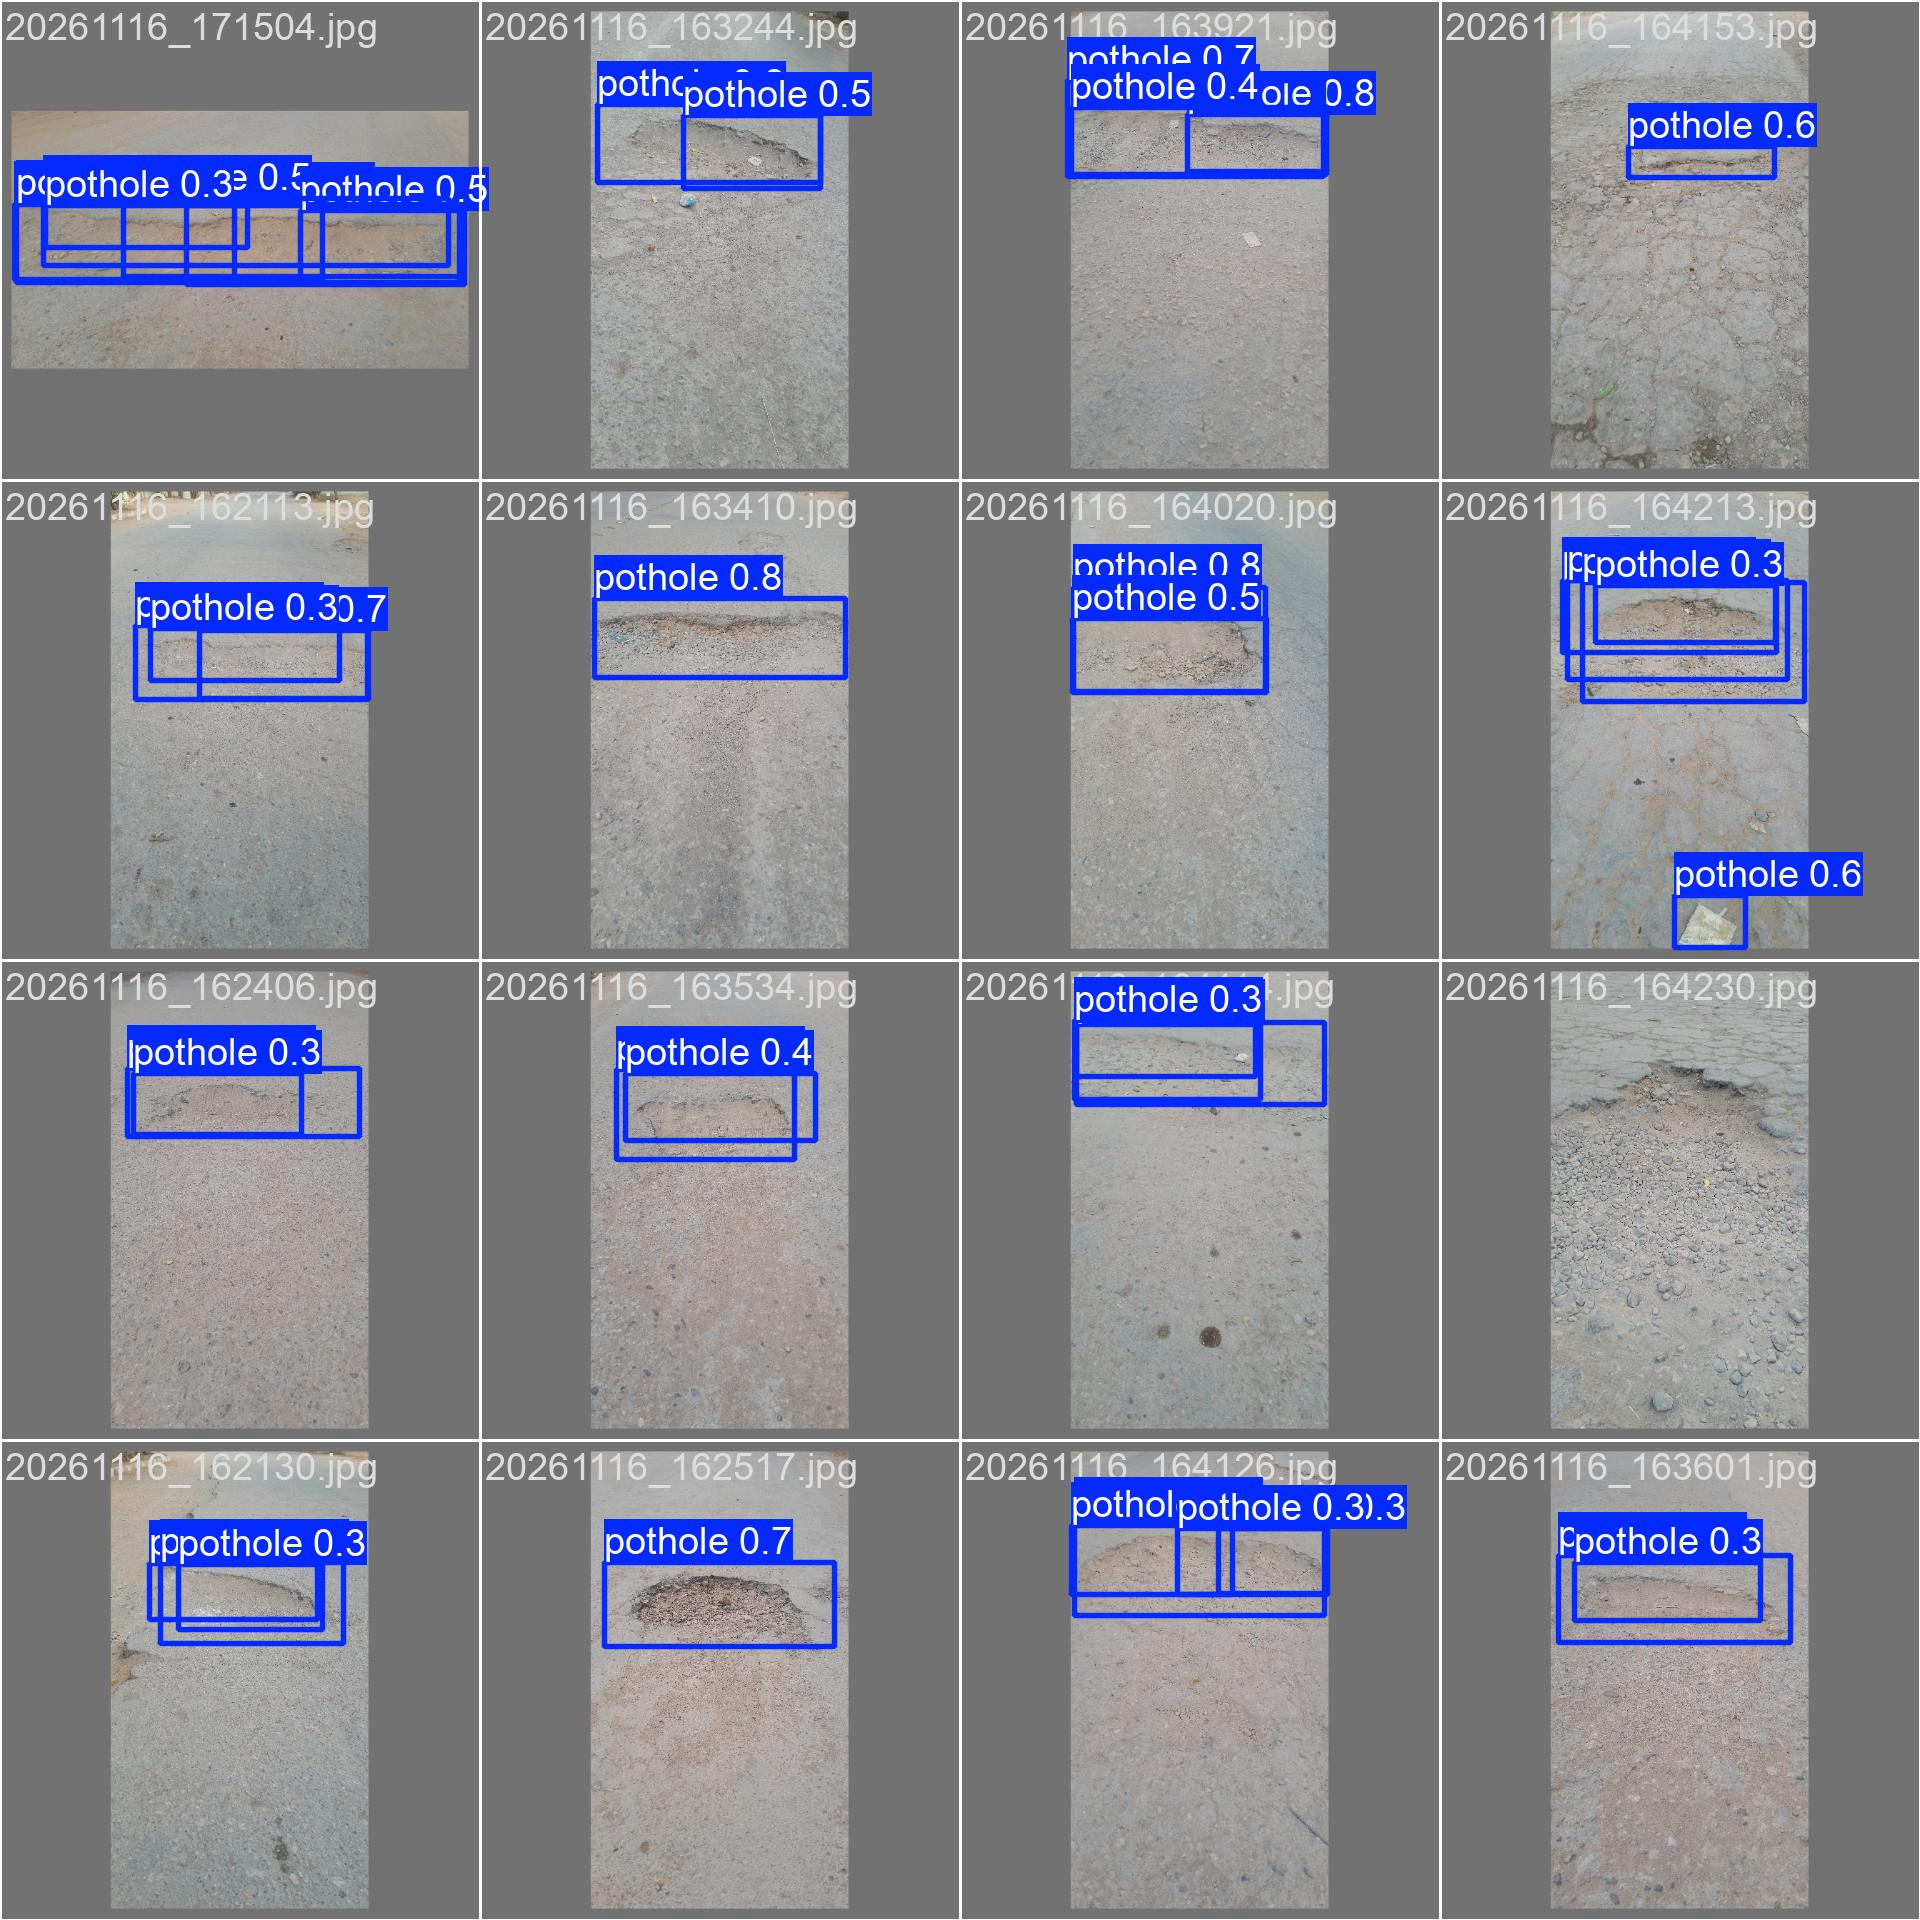

In [ ]:
import os
from IPython.display import Image, display

WORKSPACE_DIR = "/content/drive/MyDrive/CS4045_Road_Damage_Detection"

for exp_name in [
    "exp1_cross_domain_karachi_test",
    "exp2_karachi_test_eval",
    "exp3_karachi_test_eval"
]:
    pred_img = f"{WORKSPACE_DIR}/runs/{exp_name}/val_batch0_pred.jpg"
    if os.path.exists(pred_img):
        print(f"\n=== {exp_name} ===")
        display(Image(filename=pred_img, width=750))